# PGNet — tự kiểm tra trên Colab T4, từng bước

**Chưa chạy:** các bảng, ảnh và trạng thái bên dưới chỉ xuất hiện khi bạn chạy cell bằng nút ▶.
Mục tiêu: xác minh weights/runtime thực sự forward trên **9 ảnh train**. Không có ảnh test hoặc GT trong gói; không chấm Hmean/CER và không chọn winner.

1. Colab → **File → Upload notebook** → chọn notebook này.
2. **Runtime → Change runtime type → T4 GPU → Save**, rồi Connect.
3. Chạy lần lượt các cell từ trên xuống. Upload ZIP qualification nguyên bản khi được hỏi; không giải nén trước.
4. Xem ảnh, log, bảng receipt và prediction. Chỉ chuyển sang comparison khi bảng gate đều PASS.
5. **File → Save**, lưu/download notebook có outputs, rồi tải ZIP evidence ở cell cuối. Nếu lỗi, vẫn chạy riêng cell export.

Không đổi weights/config/threshold/dictionary/grouping. Receipt là bằng chứng chính; ảnh overlay chỉ giúp quan sát output native.

Runner đã sửa bootstrap và giữ đường dẫn driver NVIDIA; không cần copy cell vá bên ngoài. Upload đúng ZIP canonical bên dưới. Nếu dùng lại runtime chưa có PASS, notebook giữ log lỗi và kiểm lại cache đã cài.


In [1]:
from pathlib import Path
import sys, subprocess, json, hashlib, zipfile
from google.colab import files
hardware = subprocess.check_output(['nvidia-smi', '--query-gpu=name,memory.total,driver_version', '--format=csv,noheader'], text=True).strip()
print(hardware)
assert 'T4' in hardware, 'Chọn T4 và khởi động lại runtime trước khi tiếp tục.'
ROOT = Path('/content/joint-qualification/runner')
WORK = Path('/content/joint-qualification/work')
OUT = Path('/content/joint-qualification/evidence')
OUT.mkdir(parents=True, exist_ok=True)
(OUT/'hardware.json').write_text(json.dumps({'gpu':hardware,'kernel_python':sys.version,'model_execution_verified':False}, indent=2))

from IPython.display import display, HTML
from html import escape
def show_table(rows, columns, title):
    markup = '<h3>' + escape(title) + '</h3><div style="overflow:auto"><table border="1" cellpadding="6"><thead><tr>'
    markup += ''.join('<th>' + escape(str(k)) + '</th>' for k in columns) + '</tr></thead><tbody>'
    markup += ''.join('<tr>' + ''.join('<td style="white-space:pre-wrap;word-break:break-word">' + escape(str(r.get(k, ''))) + '</td>' for k in columns) + '</tr>' for r in rows)
    markup += '</tbody></table></div>'
    display(HTML(markup))
    return markup
show_table([{'GPU': hardware, 'Python kernel': sys.version.split()[0], 'Trạng thái': 'HARDWARE ONLY — model chưa chạy'}], ['GPU', 'Python kernel', 'Trạng thái'], 'Bước 1 — Phần cứng')


Tesla T4, 15360 MiB, 580.82.07


GPU,Python kernel,Trạng thái
"Tesla T4, 15360 MiB, 580.82.07",3.13.15,HARDWARE ONLY — model chưa chạy


'<h3>Bước 1 — Phần cứng</h3><div style="overflow:auto"><table border="1" cellpadding="6"><thead><tr><th>GPU</th><th>Python kernel</th><th>Trạng thái</th></tr></thead><tbody><tr><td style="white-space:pre-wrap;word-break:break-word">Tesla T4, 15360 MiB, 580.82.07</td><td style="white-space:pre-wrap;word-break:break-word">3.13.15</td><td style="white-space:pre-wrap;word-break:break-word">HARDWARE ONLY — model chưa chạy</td></tr></tbody></table></div>'

## Upload gói đã khóa

Gói khoảng 3,9 MB gồm code và đúng 9 ảnh train. Bạn tự chọn file upload. Cell kiểm SHA256 và mọi member trước khi giải nén.


In [2]:
uploaded = files.upload()
assert len(uploaded) == 1, 'Chọn đúng một ZIP qualification.'
filename, raw = next(iter(uploaded.items()))
assert hashlib.sha256(raw).hexdigest() == 'ee6c45d306f9684299cc0eb0492ffe962b1f3ac03cc0b31c2d3019456e01eb0a', 'Gói ZIP khác bản đã khóa.'
ROOT.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(filename) as archive:
    manifest = json.loads(archive.read('qualification-manifest.json'))
    assert manifest['test_inputs'] == 0 and len(manifest['train_inputs']) == 9
    names = archive.namelist()
    assert len(names) == len(set(names))
    assert set(names) == set(manifest['files']) | {'qualification-manifest.json'}
    for name, expected in manifest['files'].items():
        relative = Path(name)
        assert not relative.is_absolute() and '..' not in relative.parts and chr(92) not in name and ':' not in name
        assert hashlib.sha256(archive.read(name)).hexdigest() == expected
    # Preserve prior failure evidence before Step4 writes a fresh log.
    from datetime import datetime, timezone
    import shutil
    prior_manifest_path = ROOT/'qualification-manifest.json'
    if prior_manifest_path.is_file():
        prior_manifest = json.loads(prior_manifest_path.read_text())
        assert prior_manifest['train_inputs'] == manifest['train_inputs'], 'Train cohort changed.'
        if (OUT/'pgnet_totaltext_joint_t4/preflight.json').exists():
            assert prior_manifest == manifest, 'Passed run cannot be changed; choose a new output root.'
        elif (OUT/'qualification.log').is_file():
            history = OUT/'failure-history'/datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
            history.mkdir(parents=True, exist_ok=False)
            for previous in ['qualification.log','process-status.json','cuda-diagnostics.json','qualification-manifest.json']:
                if (OUT/previous).is_file():
                    shutil.copy2(OUT/previous, history/previous)
    archive.extractall(ROOT)
print('Verified:', len(manifest['train_inputs']), 'train frames; zero test frames')

show_table([{'File':filename, 'Bytes':len(raw), 'SHA256':hashlib.sha256(raw).hexdigest(), 'Train':len(manifest['train_inputs']), 'Test':manifest['test_inputs'], 'Kết quả':'PASS — đúng gói đã khóa'}], ['File','Bytes','SHA256','Train','Test','Kết quả'], 'Bước 2 — Kiểm tra gói')
(OUT/'qualification-manifest.json').write_text(json.dumps(manifest, indent=2))


Saving joint-spotting-t4-qualification-261015.zip to joint-spotting-t4-qualification-261015.zip
Verified: 9 train frames; zero test frames


File,Bytes,SHA256,Train,Test,Kết quả
joint-spotting-t4-qualification-261015.zip,3906098,ee6c45d306f9684299cc0eb0492ffe962b1f3ac03cc0b31c2d3019456e01eb0a,9,0,PASS — đúng gói đã khóa


22857

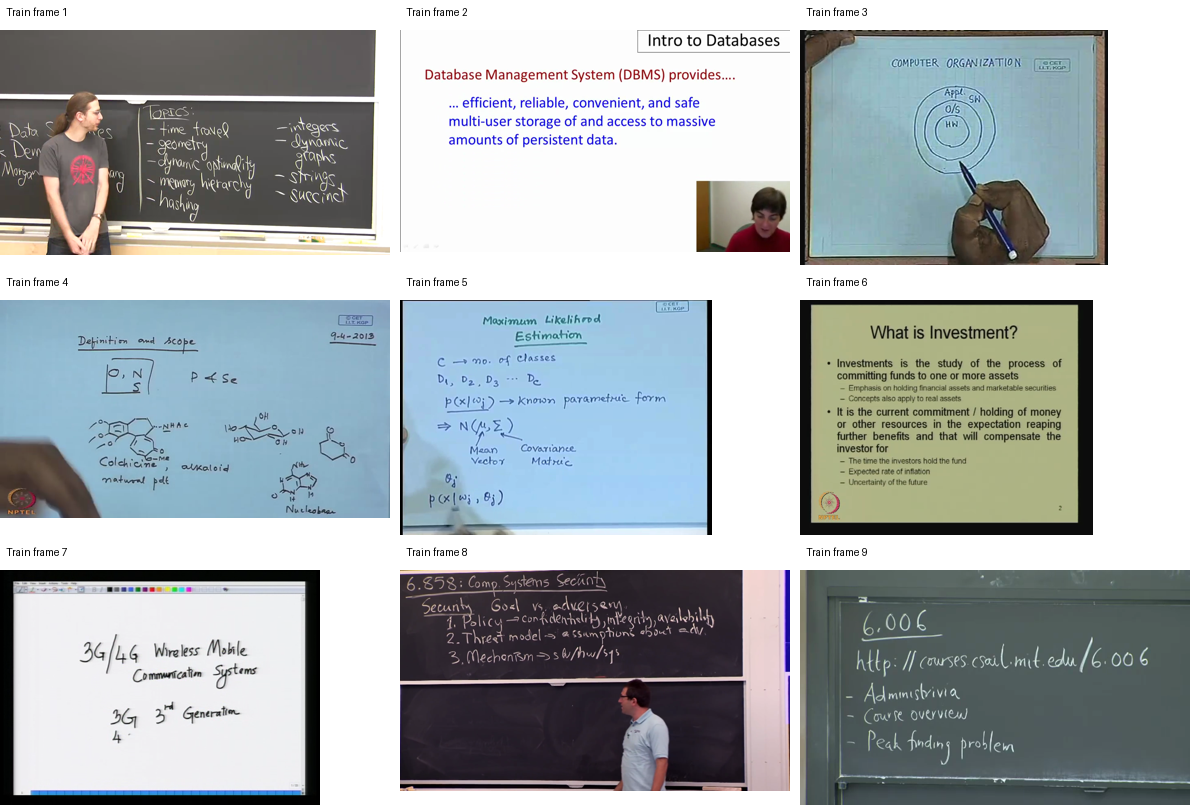

Frame ID,Width,Height,SHA256
Frames/train/1/1/00_00_50_00001.png,1280,738,16c464ae42e0b4ac274910194a58da6789bbe2041e8c1f52c04ddb3edc27a4b8
Frames/train/12/1/00_00_33_00001.png,960,546,2caa302ce5701a8425bf31baa120462dd7616933d27582fa042ffea729dda9c3
Frames/train/15/1/00_03_25_00001.png,800,610,a5e7460868f9663938314e8d126e17f570eac99f6ecf2c70b1bc9c4dcafa56ee
Frames/train/16/1/00_09_38_00001.png,864,482,bd409ec06bd42709c9a82b56997196444dbdad5b276a1b78f0e22d31f3671577
Frames/train/17/10/00_08_10_00001.png,640,482,cf709d5ad318b48b3f12e823525aeceb6264d3ed9e26f464327687f9e6157f9d
Frames/train/21/1/00_02_38_00001.png,720,578,a2507f99ee4ca07e6b9ebf08093990acb80cd7bcb4c98b68a13515720e60afe1
Frames/train/22/1/00_01_20_00001.png,787,578,1331f8f82f610b1a1f4e700c8b53dc7759434e6031bb3698006cfdad53e88df6
Frames/train/4/1/00_09_55_00001.png,1920,1090,ee4627870ad4ce956e667c21676d61b9118ab0e00e73d67721c64ea098f4c93e
Frames/train/5/1/00_01_07_00001.png,640,386,4d6a533e74dc952d04cd649d852115a1d653f71b06e57213d2da6f5fbe3719c3


'<h3>Bước 3 — Đủ 9 ảnh train, không có test</h3><div style="overflow:auto"><table border="1" cellpadding="6"><thead><tr><th>Frame ID</th><th>Width</th><th>Height</th><th>SHA256</th></tr></thead><tbody><tr><td style="white-space:pre-wrap;word-break:break-word">Frames/train/1/1/00_00_50_00001.png</td><td style="white-space:pre-wrap;word-break:break-word">1280</td><td style="white-space:pre-wrap;word-break:break-word">738</td><td style="white-space:pre-wrap;word-break:break-word">16c464ae42e0b4ac274910194a58da6789bbe2041e8c1f52c04ddb3edc27a4b8</td></tr><tr><td style="white-space:pre-wrap;word-break:break-word">Frames/train/12/1/00_00_33_00001.png</td><td style="white-space:pre-wrap;word-break:break-word">960</td><td style="white-space:pre-wrap;word-break:break-word">546</td><td style="white-space:pre-wrap;word-break:break-word">2caa302ce5701a8425bf31baa120462dd7616933d27582fa042ffea729dda9c3</td></tr><tr><td style="white-space:pre-wrap;word-break:break-word">Frames/train/15/1/00_03_25_000

In [3]:
from PIL import Image, ImageDraw
VIS = OUT/'visualizations'
VIS.mkdir(parents=True, exist_ok=True)
preview_rows = []
sheet = Image.new('RGB', (1200, 3*270), 'white')
for index, row in enumerate(manifest['train_inputs']):
    with Image.open(ROOT/row['frame_id']) as image:
        image = image.convert('RGB')
        preview_rows.append({'Frame ID':row['frame_id'], 'Width':image.width, 'Height':image.height, 'SHA256':row['image_sha256']})
        image.thumbnail((390, 235))
        x, y = (index % 3)*400, (index // 3)*270
        sheet.paste(image, (x, y+30))
        ImageDraw.Draw(sheet).text((x+6,y+6), f'Train frame {index+1}', fill='black')
sheet.save(VIS/'train-inputs.jpg')
display(sheet)
show_table(preview_rows, ['Frame ID','Width','Height','SHA256'], 'Bước 3 — Đủ 9 ảnh train, không có test')


## Bạn tự chạy cài môi trường và forward pass

Tạo môi trường Python 3.10.16 riêng, tải checkpoint PGNet chính thức đã khóa SHA, cài Paddle GPU/CUDA 11.8/cuDNN 8 riêng và chạy 9 ảnh train. Không hạ cấp Python hoặc CUDA của kernel Colab. Log được giữ cả khi thất bại.


In [4]:
import time, os, signal
command = [sys.executable, '-m', 'experiments.scripts.qualify_joint_spotting', '--root', str(ROOT), '--work', str(WORK), '--output', str(OUT)]
log = OUT/'qualification.log'
qualification_returncode = None
print('Bước 4 — Đang cài môi trường riêng và forward; cell có thể chạy lâu. Không bấm chạy lại khi còn hoạt động.')
print('Log đầy đủ:', log)
handle = display(HTML('<b>STARTING — chưa có kết quả model</b>'), display_id=True)
tail, last_update = [], 0.0
with log.open('w') as stream:
    process = subprocess.Popen(command, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, errors='replace', bufsize=1, start_new_session=True)
    try:
        for line in process.stdout:
            stream.write(line)
            stream.flush()
            tail.append(line)
            tail = tail[-40:]
            if time.monotonic()-last_update > 1:
                handle.update(HTML('<b>RUNNING — 40 dòng cuối; toàn bộ log được giữ</b><pre>' + escape(''.join(tail)) + '</pre>'))
                last_update = time.monotonic()
        qualification_returncode = process.wait()
    except KeyboardInterrupt:
        # Stop the process tree on Colab Linux; avoid orphan dependency/model jobs.
        os.killpg(process.pid, signal.SIGTERM)
        try:
            process.wait(timeout=5)
        except subprocess.TimeoutExpired:
            os.killpg(process.pid, signal.SIGKILL)
            process.wait()
        raise
handle.update(HTML('<b>' + ('PROCESS COMPLETED' if qualification_returncode == 0 else 'FAILED — giữ evidence, chưa chạy test') + '</b><pre>' + escape(''.join(tail)) + '</pre>'))
(OUT/'process-status.json').write_text(json.dumps({'returncode':qualification_returncode, 'model_pass_requires_receipt':True}, indent=2))
assert qualification_returncode == 0, 'Preflight chưa đạt. Chạy cell export cuối để giữ log; chưa chạy test.'


Bước 4 — Đang cài môi trường riêng và forward; cell có thể chạy lâu. Không bấm chạy lại khi còn hoạt động.
Log đầy đủ: /content/joint-qualification/evidence/qualification.log


## Xác nhận receipt

Chỉ coi GPU train preflight đạt khi receipt ghi `passed`, device T4 và đủ 9 train observations. Prediction geometry lỗi được ghi lại, không lọc; protocol test sẽ tính chúng là FP. Kết quả này chưa phải accuracy hoặc benchmark test.


In [5]:
receipt_path = OUT/'pgnet_totaltext_joint_t4/preflight.json'
receipt = json.loads(receipt_path.read_text()) if receipt_path.is_file() else {}
observations = receipt.get('train_observations', [])
actual_ids = [r['frame_id'] for r in observations]
expected_ids = [r['frame_id'] for r in manifest['train_inputs']]
expected_hashes = {r['frame_id']:r['image_sha256'] for r in manifest['train_inputs']}
checks = [
    ('Process vừa chạy thành công', globals().get('qualification_returncode') == 0),
    ('Receipt tồn tại', receipt_path.is_file()),
    ('status = passed', receipt.get('status') == 'passed'),
    ('Thiết bị model là T4', 'T4' in receipt.get('runtime', {}).get('device','')),
    ('Đủ đúng 9 frame ID đã khóa, không trùng', len(actual_ids) == 9 and len(set(actual_ids)) == 9 and set(actual_ids) == set(expected_ids)),
    ('Hash ảnh đúng manifest', bool(observations) and all(r.get('image_sha256') == expected_hashes.get(r['frame_id']) for r in observations)),
    ('Chỉ frame train', bool(actual_ids) and all(x.startswith('Frames/train/') for x in actual_ids)),
    ('no_test_inference = true', receipt.get('no_test_inference') is True),
    ('accuracy_not_evaluated = true', receipt.get('accuracy_not_evaluated') is True),
]
gate_rows = [{'Kiểm tra':name, 'Kết quả':'PASS' if passed else 'FAIL'} for name, passed in checks]
gate_html = show_table(gate_rows, ['Kiểm tra','Kết quả'], 'Bước 5 — Receipt gate')
(OUT/'receipt-gates.html').write_text(gate_html, encoding='utf-8')
(OUT/'receipt-gates.json').write_text(json.dumps(gate_rows, ensure_ascii=False, indent=2), encoding='utf-8')
display(HTML('<details><summary>Runtime và binding đầy đủ</summary><pre>' + escape(json.dumps({'runtime':receipt.get('runtime'), 'binding':receipt.get('binding')}, ensure_ascii=False, indent=2)) + '</pre></details>'))
assert all(passed for _, passed in checks), 'Gate FAIL: giữ evidence; chưa chuyển sang full test.'
print('PASS: actual T4 train-forward đủ 9 ảnh. Đây chưa phải kết quả accuracy hoặc benchmark test.')


Kiểm tra,Kết quả
Process vừa chạy thành công,PASS
Receipt tồn tại,PASS
status = passed,PASS
Thiết bị model là T4,PASS
"Đủ đúng 9 frame ID đã khóa, không trùng",PASS
Hash ảnh đúng manifest,PASS
Chỉ frame train,PASS
no_test_inference = true,PASS
accuracy_not_evaluated = true,PASS


PASS: actual T4 train-forward đủ 9 ảnh. Đây chưa phải kết quả accuracy hoặc benchmark test.


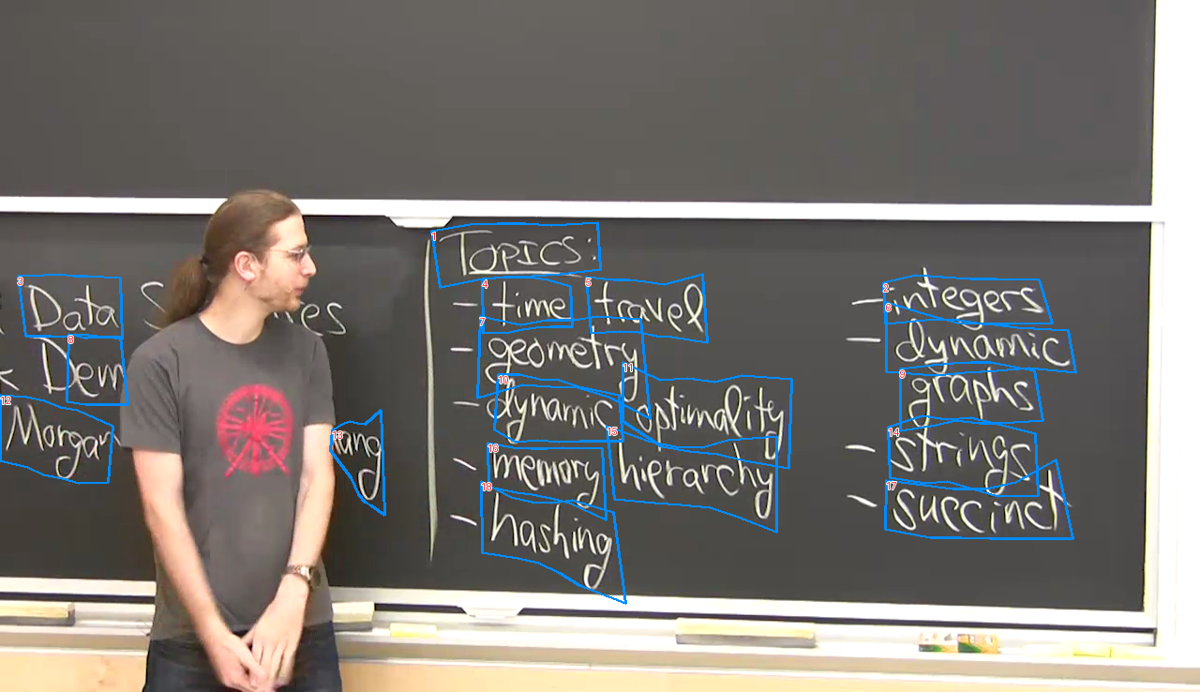

Region,Text,Polygon,Overlay
1,toprcs,"[[460.0, 246.0], [501.0, 239.0], [530.0, 238.0], [560.0, 238.0], [588.0, 240.0], [637.0, 237.0], [640.0, 287.0], [597.0, 292.0], [567.0, 294.0], [537.0, 295.0], [509.0, 298.0], [469.0, 306.0]]",drawn
2,integers,"[[942.0, 301.0], [976.0, 293.0], [1005.0, 295.0], [1034.0, 297.0], [1062.0, 297.0], [1108.0, 298.0], [1122.0, 344.0], [1075.0, 345.0], [1047.0, 345.0], [1016.0, 340.0], [987.0, 341.0], [944.0, 345.0]]",drawn
3,data,"[[19.0, 294.0], [46.0, 293.0], [63.0, 292.0], [78.0, 294.0], [93.0, 294.0], [128.0, 296.0], [130.0, 361.0], [94.0, 357.0], [80.0, 356.0], [67.0, 359.0], [54.0, 358.0], [27.0, 358.0]]",drawn
4,fime,"[[514.0, 297.0], [540.0, 295.0], [555.0, 295.0], [570.0, 296.0], [584.0, 298.0], [608.0, 305.0], [610.0, 348.0], [586.0, 348.0], [571.0, 349.0], [557.0, 351.0], [543.0, 354.0], [515.0, 355.0]]",drawn
5,frave,"[[625.0, 295.0], [654.0, 298.0], [671.0, 298.0], [688.0, 300.0], [708.0, 303.0], [749.0, 292.0], [754.0, 365.0], [716.0, 359.0], [700.0, 358.0], [681.0, 354.0], [661.0, 353.0], [630.0, 355.0]]",drawn
6,dynamic,"[[945.0, 322.0], [988.0, 335.0], [1021.0, 344.0], [1053.0, 345.0], [1085.0, 349.0], [1139.0, 352.0], [1147.0, 397.0], [1097.0, 392.0], [1063.0, 395.0], [1029.0, 397.0], [997.0, 400.0], [945.0, 396.0]]",drawn
7,geomery,"[[512.0, 337.0], [555.0, 346.0], [583.0, 341.0], [612.0, 341.0], [637.0, 337.0], [683.0, 340.0], [693.0, 446.0], [649.0, 423.0], [616.0, 413.0], [587.0, 412.0], [557.0, 410.0], [509.0, 424.0]]",drawn
8,ew,"[[73.0, 356.0], [90.0, 360.0], [93.0, 360.0], [97.0, 359.0], [100.0, 359.0], [128.0, 359.0], [136.0, 431.0], [102.0, 431.0], [98.0, 431.0], [95.0, 431.0], [91.0, 431.0], [71.0, 428.0]]",drawn
9,graphs,"[[960.0, 393.0], [994.0, 389.0], [1016.0, 387.0], [1035.0, 386.0], [1056.0, 386.0], [1103.0, 395.0], [1112.0, 448.0], [1066.0, 451.0], [1044.0, 451.0], [1019.0, 448.0], [998.0, 453.0], [960.0, 459.0]]",drawn
10,yhamic,"[[531.0, 399.0], [554.0, 399.0], [575.0, 404.0], [596.0, 405.0], [617.0, 412.0], [660.0, 421.0], [664.0, 470.0], [618.0, 470.0], [596.0, 471.0], [573.0, 469.0], [550.0, 471.0], [527.0, 458.0]]",drawn


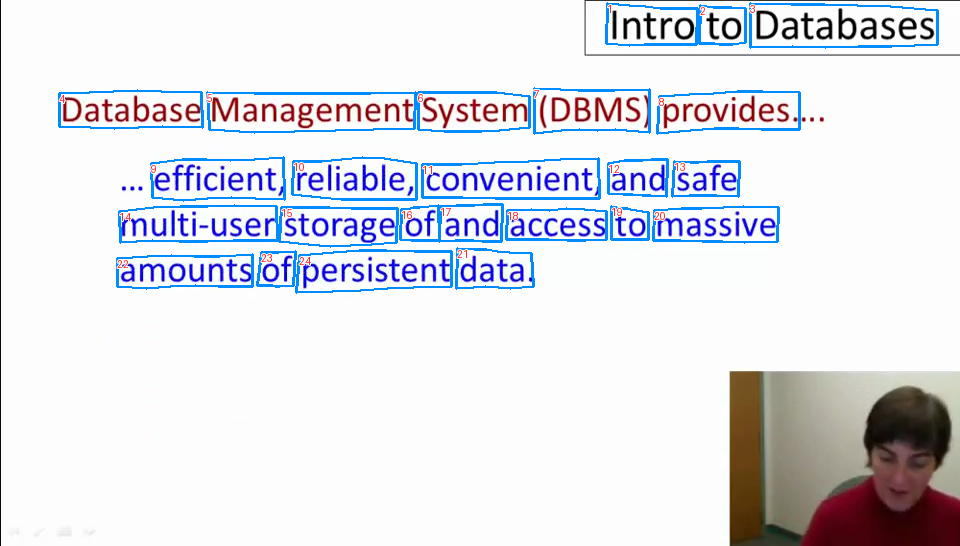

Region,Text,Polygon,Overlay
1,intro,"[[607.0, 3.0], [629.0, 5.0], [645.0, 6.0], [660.0, 8.0], [675.0, 8.0], [697.0, 8.0], [696.0, 44.0], [674.0, 44.0], [659.0, 44.0], [644.0, 44.0], [629.0, 45.0], [606.0, 43.0]]",drawn
2,to,"[[700.0, 5.0], [713.0, 7.0], [720.0, 7.0], [725.0, 7.0], [731.0, 7.0], [745.0, 8.0], [745.0, 42.0], [732.0, 44.0], [726.0, 44.0], [719.0, 44.0], [714.0, 43.0], [699.0, 43.0]]",drawn
3,databases,"[[750.0, 3.0], [791.0, 4.0], [824.0, 4.0], [857.0, 5.0], [890.0, 6.0], [937.0, 10.0], [937.0, 44.0], [891.0, 46.0], [858.0, 46.0], [825.0, 47.0], [792.0, 46.0], [750.0, 47.0]]",drawn
4,database,"[[59.0, 93.0], [89.0, 92.0], [113.0, 91.0], [137.0, 90.0], [161.0, 91.0], [201.0, 92.0], [202.0, 127.0], [162.0, 126.0], [138.0, 127.0], [114.0, 128.0], [90.0, 127.0], [59.0, 126.0]]",drawn
5,management,"[[207.0, 92.0], [254.0, 93.0], [293.0, 93.0], [330.0, 93.0], [370.0, 93.0], [415.0, 92.0], [414.0, 128.0], [373.0, 129.0], [335.0, 130.0], [294.0, 131.0], [254.0, 132.0], [209.0, 129.0]]",drawn
6,system,"[[418.0, 92.0], [443.0, 92.0], [460.0, 92.0], [478.0, 92.0], [496.0, 92.0], [529.0, 96.0], [529.0, 127.0], [499.0, 130.0], [481.0, 131.0], [463.0, 131.0], [444.0, 131.0], [418.0, 129.0]]",drawn
7,dbms,"[[534.0, 88.0], [560.0, 89.0], [578.0, 90.0], [596.0, 90.0], [614.0, 90.0], [649.0, 89.0], [649.0, 132.0], [615.0, 129.0], [597.0, 130.0], [579.0, 129.0], [561.0, 130.0], [534.0, 133.0]]",drawn
8,provides,"[[659.0, 96.0], [689.0, 94.0], [713.0, 93.0], [737.0, 91.0], [762.0, 91.0], [799.0, 92.0], [799.0, 129.0], [761.0, 129.0], [738.0, 128.0], [714.0, 128.0], [690.0, 130.0], [657.0, 133.0]]",drawn
9,efficient,"[[151.0, 163.0], [182.0, 159.0], [206.0, 159.0], [230.0, 160.0], [254.0, 159.0], [283.0, 157.0], [284.0, 199.0], [255.0, 198.0], [231.0, 197.0], [207.0, 198.0], [183.0, 200.0], [152.0, 197.0]]",drawn
10,reliable,"[[293.0, 161.0], [321.0, 161.0], [341.0, 159.0], [362.0, 157.0], [384.0, 158.0], [416.0, 163.0], [416.0, 199.0], [383.0, 199.0], [363.0, 199.0], [341.0, 199.0], [320.0, 197.0], [292.0, 194.0]]",drawn


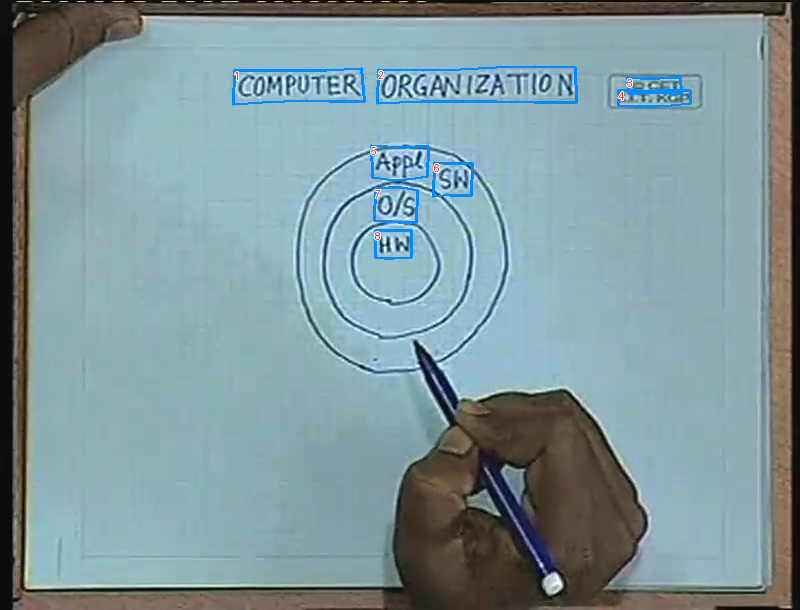

Region,Text,Polygon,Overlay
1,computer,"[[234.0, 70.0], [262.0, 70.0], [284.0, 70.0], [306.0, 70.0], [326.0, 70.0], [361.0, 68.0], [364.0, 101.0], [329.0, 101.0], [306.0, 100.0], [284.0, 101.0], [262.0, 102.0], [233.0, 104.0]]",drawn
2,organization,"[[378.0, 69.0], [422.0, 70.0], [460.0, 69.0], [496.0, 67.0], [534.0, 66.0], [575.0, 67.0], [576.0, 102.0], [534.0, 102.0], [496.0, 101.0], [457.0, 101.0], [421.0, 101.0], [377.0, 103.0]]",drawn
3,occt,"[[627.0, 77.0], [640.0, 78.0], [649.0, 78.0], [659.0, 78.0], [668.0, 77.0], [680.0, 77.0], [681.0, 93.0], [669.0, 93.0], [659.0, 92.0], [650.0, 92.0], [641.0, 93.0], [628.0, 93.0]]",drawn
4,utkgo,"[[618.0, 90.0], [634.0, 90.0], [646.0, 91.0], [659.0, 90.0], [671.0, 90.0], [690.0, 90.0], [690.0, 103.0], [671.0, 105.0], [659.0, 106.0], [647.0, 106.0], [634.0, 106.0], [618.0, 105.0]]",drawn
5,appl,"[[371.0, 145.0], [387.0, 146.0], [396.0, 147.0], [406.0, 147.0], [415.0, 146.0], [428.0, 146.0], [427.0, 176.0], [415.0, 178.0], [406.0, 179.0], [396.0, 180.0], [387.0, 179.0], [372.0, 177.0]]",drawn
6,sh,"[[434.0, 162.0], [443.0, 163.0], [446.0, 163.0], [449.0, 163.0], [453.0, 163.0], [472.0, 163.0], [471.0, 195.0], [453.0, 195.0], [450.0, 195.0], [446.0, 194.0], [443.0, 195.0], [433.0, 196.0]]",drawn
7,os,"[[375.0, 188.0], [388.0, 187.0], [394.0, 187.0], [401.0, 187.0], [407.0, 188.0], [417.0, 190.0], [416.0, 222.0], [405.0, 222.0], [398.0, 222.0], [392.0, 221.0], [386.0, 221.0], [374.0, 220.0]]",drawn
8,hw,"[[375.0, 230.0], [384.0, 230.0], [387.0, 230.0], [390.0, 230.0], [393.0, 230.0], [411.0, 230.0], [411.0, 257.0], [393.0, 258.0], [390.0, 258.0], [387.0, 258.0], [384.0, 258.0], [375.0, 257.0]]",drawn


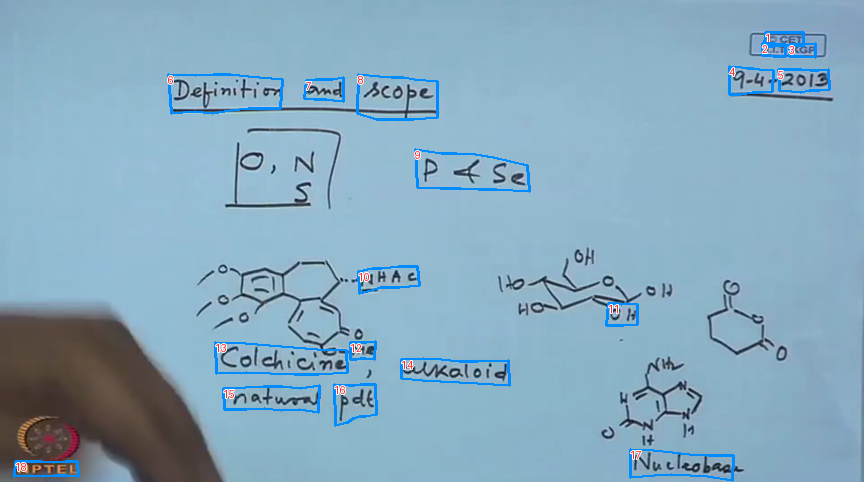

Region,Text,Polygon,Overlay
1,ocet,"[[765.0, 32.0], [774.0, 32.0], [780.0, 32.0], [786.0, 32.0], [792.0, 32.0], [803.0, 32.0], [803.0, 46.0], [791.0, 45.0], [785.0, 45.0], [779.0, 45.0], [773.0, 46.0], [764.0, 46.0]]",drawn
2,llt,"[[762.0, 43.0], [768.0, 43.0], [771.0, 43.0], [774.0, 43.0], [777.0, 44.0], [785.0, 44.0], [785.0, 56.0], [776.0, 56.0], [773.0, 56.0], [770.0, 55.0], [767.0, 55.0], [762.0, 55.0]]",drawn
3,kgp,"[[789.0, 44.0], [795.0, 44.0], [798.0, 43.0], [801.0, 44.0], [804.0, 44.0], [815.0, 43.0], [815.0, 57.0], [803.0, 56.0], [800.0, 56.0], [797.0, 56.0], [794.0, 56.0], [789.0, 56.0]]",drawn
4,i4,"[[729.0, 66.0], [741.0, 67.0], [747.0, 68.0], [753.0, 68.0], [759.0, 69.0], [773.0, 70.0], [772.0, 91.0], [758.0, 92.0], [752.0, 92.0], [746.0, 93.0], [740.0, 94.0], [729.0, 94.0]]",drawn
5,2013,"[[778.0, 69.0], [792.0, 69.0], [801.0, 69.0], [810.0, 70.0], [818.0, 70.0], [828.0, 69.0], [829.0, 89.0], [819.0, 90.0], [809.0, 90.0], [800.0, 92.0], [791.0, 91.0], [779.0, 90.0]]",drawn
6,deinition,"[[168.0, 74.0], [195.0, 75.0], [213.0, 74.0], [230.0, 74.0], [248.0, 76.0], [282.0, 79.0], [280.0, 108.0], [248.0, 108.0], [230.0, 110.0], [212.0, 113.0], [194.0, 111.0], [171.0, 113.0]]",drawn
7,omd,"[[306.0, 80.0], [315.0, 79.0], [321.0, 79.0], [327.0, 79.0], [332.0, 79.0], [343.0, 77.0], [343.0, 101.0], [333.0, 100.0], [326.0, 99.0], [320.0, 99.0], [314.0, 99.0], [304.0, 98.0]]",drawn
8,scope,"[[358.0, 74.0], [379.0, 76.0], [391.0, 77.0], [403.0, 77.0], [414.0, 79.0], [437.0, 81.0], [437.0, 117.0], [413.0, 119.0], [400.0, 119.0], [388.0, 119.0], [376.0, 119.0], [357.0, 113.0]]",drawn
9,p4se,"[[415.0, 149.0], [441.0, 153.0], [456.0, 153.0], [475.0, 154.0], [493.0, 157.0], [527.0, 165.0], [529.0, 191.0], [496.0, 189.0], [478.0, 189.0], [460.0, 188.0], [440.0, 188.0], [417.0, 187.0]]",drawn
10,nhae,"[[358.0, 271.0], [372.0, 268.0], [381.0, 268.0], [390.0, 267.0], [398.0, 266.0], [417.0, 266.0], [419.0, 285.0], [399.0, 287.0], [389.0, 287.0], [380.0, 287.0], [371.0, 290.0], [359.0, 293.0]]",drawn


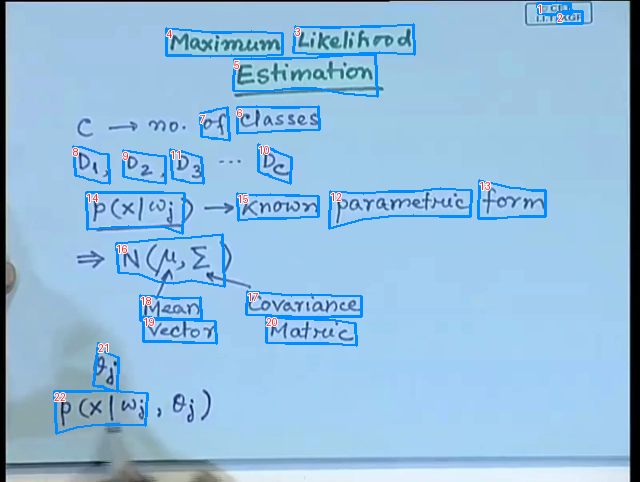

Region,Text,Polygon,Overlay
1,ocet,"[[537.0, 3.0], [545.0, 3.0], [551.0, 3.0], [556.0, 2.0], [562.0, 3.0], [570.0, 3.0], [571.0, 13.0], [563.0, 13.0], [557.0, 14.0], [551.0, 14.0], [545.0, 14.0], [538.0, 13.0]]",drawn
2,kgp,"[[557.0, 12.0], [562.0, 11.0], [565.0, 11.0], [568.0, 11.0], [571.0, 11.0], [582.0, 11.0], [582.0, 23.0], [571.0, 23.0], [568.0, 23.0], [565.0, 23.0], [562.0, 23.0], [557.0, 23.0]]",drawn
3,likelikrod,"[[295.0, 26.0], [320.0, 27.0], [340.0, 27.0], [360.0, 26.0], [380.0, 26.0], [413.0, 24.0], [414.0, 54.0], [379.0, 52.0], [359.0, 53.0], [339.0, 54.0], [319.0, 54.0], [293.0, 52.0]]",drawn
4,maximum,"[[166.0, 28.0], [191.0, 30.0], [211.0, 32.0], [231.0, 32.0], [251.0, 31.0], [282.0, 33.0], [282.0, 54.0], [251.0, 56.0], [231.0, 55.0], [210.0, 56.0], [191.0, 55.0], [166.0, 55.0]]",drawn
5,estimahion,"[[234.0, 59.0], [266.0, 58.0], [291.0, 58.0], [317.0, 57.0], [342.0, 55.0], [375.0, 54.0], [377.0, 96.0], [343.0, 93.0], [316.0, 88.0], [291.0, 88.0], [265.0, 91.0], [233.0, 90.0]]",drawn
6,casses,"[[237.0, 107.0], [256.0, 106.0], [271.0, 107.0], [285.0, 107.0], [299.0, 107.0], [318.0, 106.0], [319.0, 129.0], [300.0, 130.0], [285.0, 130.0], [271.0, 131.0], [257.0, 132.0], [237.0, 133.0]]",drawn
7,of,"[[200.0, 113.0], [208.0, 111.0], [211.0, 111.0], [213.0, 110.0], [216.0, 109.0], [227.0, 107.0], [229.0, 140.0], [217.0, 138.0], [214.0, 138.0], [211.0, 138.0], [208.0, 137.0], [201.0, 136.0]]",drawn
8,di,"[[73.0, 146.0], [82.0, 147.0], [88.0, 149.0], [94.0, 151.0], [99.0, 153.0], [108.0, 154.0], [109.0, 183.0], [100.0, 182.0], [94.0, 180.0], [88.0, 179.0], [83.0, 177.0], [75.0, 175.0]]",drawn
9,d2,"[[123.0, 150.0], [130.0, 151.0], [136.0, 152.0], [142.0, 153.0], [148.0, 154.0], [165.0, 156.0], [165.0, 183.0], [148.0, 181.0], [143.0, 180.0], [137.0, 179.0], [131.0, 178.0], [123.0, 176.0]]",drawn
10,de,"[[258.0, 144.0], [266.0, 148.0], [270.0, 148.0], [272.0, 149.0], [275.0, 151.0], [291.0, 157.0], [290.0, 183.0], [272.0, 177.0], [270.0, 176.0], [267.0, 174.0], [264.0, 174.0], [258.0, 171.0]]",drawn


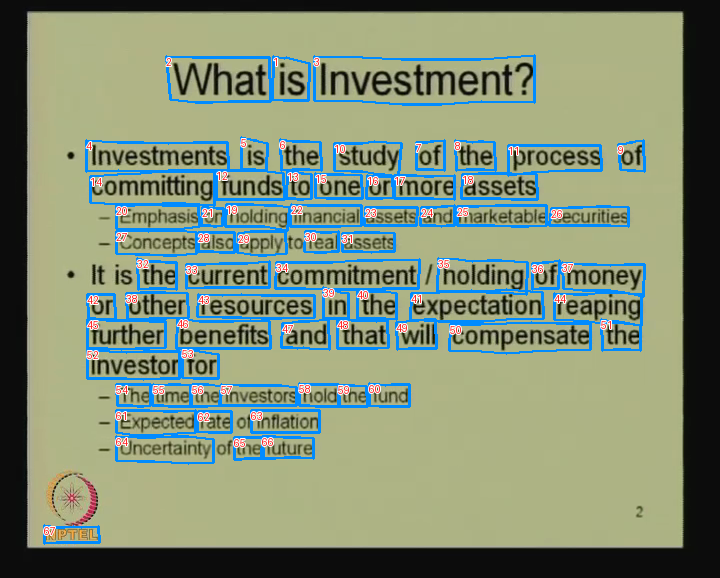

Region,Text,Polygon,Overlay
1,is,"[[273.0, 56.0], [284.0, 58.0], [284.0, 58.0], [286.0, 57.0], [289.0, 58.0], [309.0, 63.0], [308.0, 100.0], [289.0, 100.0], [286.0, 100.0], [283.0, 100.0], [283.0, 100.0], [272.0, 99.0]]",drawn
2,what,"[[166.0, 56.0], [192.0, 57.0], [209.0, 57.0], [227.0, 57.0], [244.0, 57.0], [269.0, 57.0], [270.0, 101.0], [245.0, 101.0], [228.0, 101.0], [212.0, 102.0], [195.0, 102.0], [170.0, 99.0]]",drawn
3,investment,"[[314.0, 56.0], [362.0, 57.0], [401.0, 59.0], [441.0, 59.0], [480.0, 59.0], [534.0, 55.0], [534.0, 102.0], [481.0, 101.0], [441.0, 104.0], [402.0, 104.0], [362.0, 101.0], [314.0, 100.0]]",drawn
4,investments,"[[86.0, 140.0], [117.0, 142.0], [143.0, 142.0], [168.0, 143.0], [193.0, 142.0], [227.0, 142.0], [228.0, 169.0], [194.0, 170.0], [168.0, 170.0], [143.0, 171.0], [118.0, 170.0], [86.0, 171.0]]",drawn
5,is,"[[241.0, 137.0], [250.0, 139.0], [253.0, 140.0], [256.0, 140.0], [258.0, 141.0], [267.0, 143.0], [266.0, 170.0], [258.0, 170.0], [255.0, 169.0], [253.0, 169.0], [250.0, 169.0], [241.0, 168.0]]",drawn
6,the,"[[280.0, 139.0], [292.0, 141.0], [298.0, 141.0], [303.0, 141.0], [309.0, 141.0], [320.0, 142.0], [321.0, 170.0], [309.0, 169.0], [303.0, 169.0], [298.0, 169.0], [292.0, 169.0], [281.0, 170.0]]",drawn
7,of,"[[416.0, 142.0], [424.0, 142.0], [427.0, 142.0], [430.0, 141.0], [433.0, 141.0], [444.0, 140.0], [444.0, 170.0], [433.0, 169.0], [430.0, 169.0], [427.0, 169.0], [424.0, 169.0], [416.0, 169.0]]",drawn
8,the,"[[455.0, 140.0], [466.0, 141.0], [472.0, 142.0], [478.0, 141.0], [483.0, 141.0], [494.0, 142.0], [495.0, 170.0], [484.0, 169.0], [478.0, 169.0], [472.0, 169.0], [466.0, 169.0], [456.0, 170.0]]",drawn
9,of,"[[618.0, 144.0], [626.0, 143.0], [629.0, 142.0], [632.0, 142.0], [635.0, 141.0], [643.0, 140.0], [644.0, 171.0], [635.0, 170.0], [633.0, 170.0], [630.0, 170.0], [627.0, 170.0], [620.0, 169.0]]",drawn
10,study,"[[334.0, 143.0], [351.0, 143.0], [362.0, 143.0], [374.0, 141.0], [386.0, 142.0], [401.0, 143.0], [398.0, 176.0], [384.0, 174.0], [373.0, 173.0], [362.0, 171.0], [351.0, 171.0], [334.0, 170.0]]",drawn


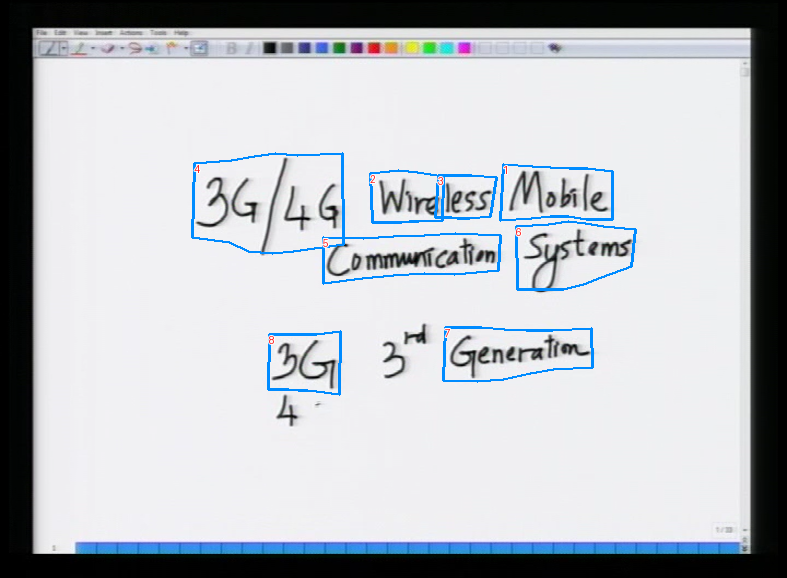

Region,Text,Polygon,Overlay
1,mobile,"[[503.0, 164.0], [532.0, 166.0], [550.0, 167.0], [569.0, 168.0], [587.0, 168.0], [612.0, 171.0], [612.0, 219.0], [586.0, 219.0], [568.0, 216.0], [550.0, 216.0], [531.0, 218.0], [500.0, 220.0]]",drawn
2,wire,"[[370.0, 173.0], [389.0, 171.0], [398.0, 170.0], [408.0, 171.0], [417.0, 172.0], [443.0, 176.0], [442.0, 220.0], [418.0, 221.0], [409.0, 221.0], [401.0, 222.0], [392.0, 222.0], [372.0, 222.0]]",drawn
3,less,"[[438.0, 175.0], [452.0, 175.0], [458.0, 175.0], [464.0, 175.0], [471.0, 175.0], [496.0, 177.0], [490.0, 216.0], [469.0, 218.0], [463.0, 218.0], [457.0, 218.0], [451.0, 217.0], [435.0, 217.0]]",drawn
4,3al,"[[194.0, 163.0], [231.0, 160.0], [254.0, 156.0], [275.0, 153.0], [297.0, 155.0], [342.0, 153.0], [343.0, 244.0], [293.0, 251.0], [272.0, 253.0], [248.0, 251.0], [229.0, 242.0], [192.0, 237.0]]",drawn
5,commicaton,"[[323.0, 237.0], [363.0, 238.0], [393.0, 236.0], [424.0, 235.0], [455.0, 233.0], [500.0, 235.0], [498.0, 270.0], [454.0, 274.0], [424.0, 273.0], [393.0, 275.0], [362.0, 278.0], [323.0, 283.0]]",drawn
6,systems,"[[516.0, 226.0], [548.0, 224.0], [568.0, 221.0], [585.0, 223.0], [603.0, 226.0], [635.0, 229.0], [631.0, 266.0], [601.0, 277.0], [583.0, 284.0], [563.0, 289.0], [545.0, 289.0], [517.0, 289.0]]",drawn
7,generattm,"[[445.0, 327.0], [481.0, 327.0], [504.0, 329.0], [526.0, 330.0], [552.0, 330.0], [591.0, 328.0], [592.0, 367.0], [553.0, 369.0], [530.0, 373.0], [503.0, 379.0], [477.0, 381.0], [443.0, 380.0]]",drawn
8,36,"[[269.0, 334.0], [289.0, 334.0], [298.0, 334.0], [307.0, 334.0], [316.0, 334.0], [340.0, 331.0], [339.0, 394.0], [316.0, 391.0], [307.0, 390.0], [298.0, 390.0], [288.0, 389.0], [268.0, 389.0]]",drawn


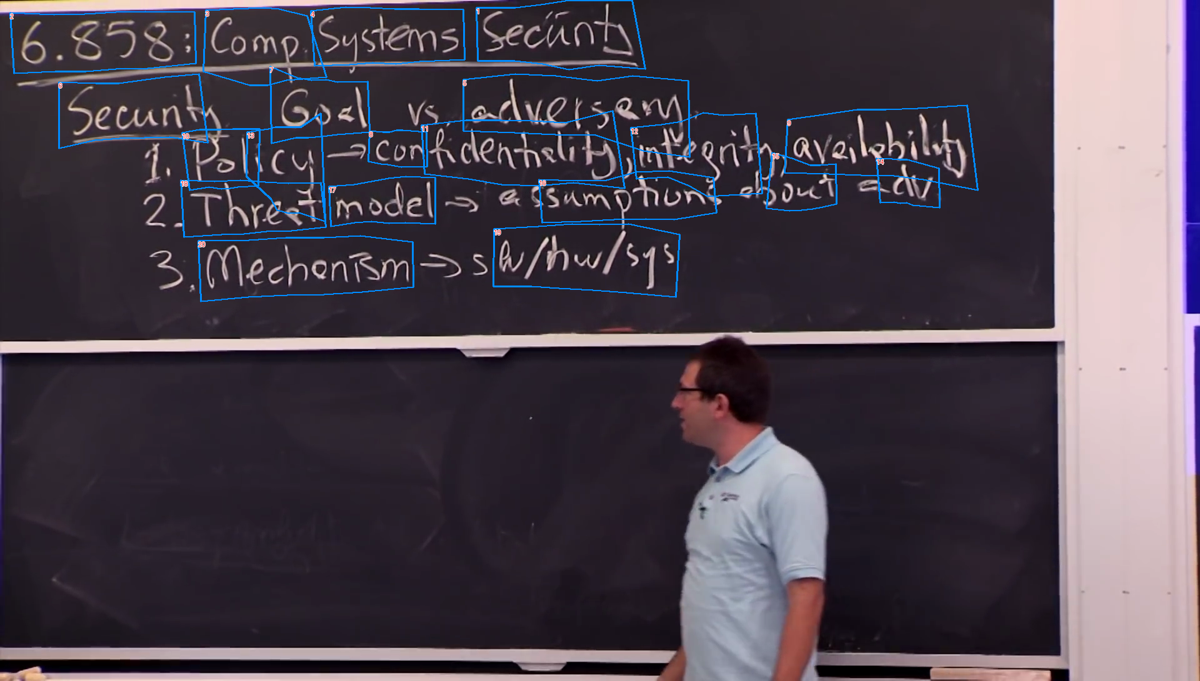

Region,Text,Polygon,Overlay
1,secianh,"[[762.0, 12.0], [824.0, 12.0], [865.0, 7.0], [911.0, 0.0], [950.0, 0.0], [1011.0, 0.0], [1032.0, 110.0], [958.0, 104.0], [910.0, 111.0], [868.0, 102.0], [823.0, 97.0], [764.0, 97.0]]",drawn
2,6658,"[[16.0, 20.0], [86.0, 23.0], [135.0, 22.0], [185.0, 19.0], [232.0, 18.0], [311.0, 19.0], [313.0, 101.0], [236.0, 109.0], [185.0, 110.0], [137.0, 114.0], [88.0, 114.0], [22.0, 117.0]]",drawn
3,comp,"[[329.0, 16.0], [373.0, 14.0], [397.0, 13.0], [422.0, 12.0], [446.0, 14.0], [491.0, 25.0], [522.0, 123.0], [458.0, 128.0], [428.0, 136.0], [399.0, 136.0], [369.0, 127.0], [325.0, 114.0]]",drawn
4,systens,"[[497.0, 17.0], [553.0, 11.0], [592.0, 12.0], [631.0, 14.0], [670.0, 14.0], [741.0, 15.0], [743.0, 95.0], [671.0, 98.0], [633.0, 102.0], [596.0, 100.0], [559.0, 103.0], [503.0, 105.0]]",drawn
5,odversey,"[[741.0, 127.0], [824.0, 118.0], [889.0, 121.0], [955.0, 129.0], [1012.0, 121.0], [1101.0, 129.0], [1103.0, 251.0], [1029.0, 241.0], [953.0, 216.0], [888.0, 215.0], [823.0, 212.0], [741.0, 209.0]]",drawn
6,secuan,"[[94.0, 131.0], [153.0, 133.0], [190.0, 133.0], [226.0, 128.0], [263.0, 123.0], [318.0, 118.0], [332.0, 228.0], [271.0, 219.0], [231.0, 220.0], [191.0, 221.0], [151.0, 224.0], [94.0, 237.0]]",drawn
7,go,"[[432.0, 106.0], [475.0, 124.0], [498.0, 128.0], [521.0, 127.0], [540.0, 131.0], [588.0, 130.0], [591.0, 211.0], [539.0, 215.0], [515.0, 218.0], [493.0, 220.0], [473.0, 220.0], [434.0, 229.0]]",drawn
8,con,"[[591.0, 209.0], [612.0, 211.0], [623.0, 211.0], [634.0, 208.0], [644.0, 208.0], [682.0, 211.0], [683.0, 266.0], [642.0, 267.0], [631.0, 265.0], [620.0, 263.0], [609.0, 262.0], [589.0, 258.0]]",drawn
9,ayalrbily,"[[1260.0, 191.0], [1324.0, 182.0], [1371.0, 175.0], [1417.0, 175.0], [1468.0, 173.0], [1547.0, 168.0], [1564.0, 304.0], [1477.0, 287.0], [1430.0, 281.0], [1377.0, 280.0], [1326.0, 278.0], [1255.0, 276.0]]",drawn
10,ppol,"[[291.0, 212.0], [319.0, 207.0], [334.0, 207.0], [352.0, 207.0], [372.0, 206.0], [415.0, 206.0], [413.0, 297.0], [380.0, 299.0], [368.0, 301.0], [354.0, 302.0], [334.0, 299.0], [303.0, 304.0]]",drawn


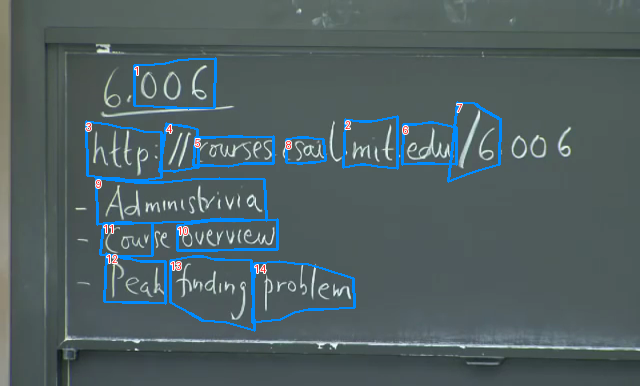

Region,Text,Polygon,Overlay
1,006,"[[134.0, 65.0], [154.0, 64.0], [165.0, 63.0], [177.0, 60.0], [188.0, 59.0], [215.0, 58.0], [214.0, 107.0], [188.0, 108.0], [176.0, 107.0], [165.0, 107.0], [153.0, 106.0], [134.0, 105.0]]",drawn
2,mil,"[[345.0, 119.0], [359.0, 121.0], [365.0, 121.0], [371.0, 121.0], [377.0, 120.0], [397.0, 116.0], [397.0, 168.0], [377.0, 166.0], [371.0, 165.0], [365.0, 164.0], [360.0, 164.0], [343.0, 167.0]]",drawn
3,http,"[[86.0, 121.0], [108.0, 124.0], [120.0, 127.0], [132.0, 128.0], [143.0, 131.0], [161.0, 132.0], [161.0, 177.0], [142.0, 180.0], [130.0, 180.0], [119.0, 178.0], [108.0, 178.0], [87.0, 175.0]]",drawn
4,11,"[[166.0, 123.0], [178.0, 125.0], [181.0, 125.0], [183.0, 126.0], [187.0, 126.0], [197.0, 129.0], [198.0, 167.0], [178.0, 170.0], [175.0, 171.0], [173.0, 171.0], [170.0, 170.0], [159.0, 171.0]]",drawn
5,cowrses,"[[195.0, 137.0], [215.0, 137.0], [228.0, 136.0], [242.0, 136.0], [256.0, 137.0], [273.0, 136.0], [273.0, 163.0], [257.0, 163.0], [243.0, 163.0], [228.0, 166.0], [213.0, 165.0], [193.0, 165.0]]",drawn
6,edu,"[[403.0, 124.0], [416.0, 124.0], [422.0, 123.0], [428.0, 122.0], [433.0, 122.0], [456.0, 127.0], [456.0, 164.0], [434.0, 163.0], [428.0, 163.0], [423.0, 163.0], [417.0, 163.0], [402.0, 164.0]]",drawn
7,l6,"[[457.0, 102.0], [474.0, 103.0], [476.0, 104.0], [478.0, 106.0], [481.0, 108.0], [500.0, 119.0], [499.0, 164.0], [478.0, 170.0], [475.0, 171.0], [472.0, 172.0], [469.0, 173.0], [448.0, 181.0]]",drawn
8,sau,"[[286.0, 139.0], [297.0, 137.0], [302.0, 137.0], [308.0, 137.0], [313.0, 138.0], [323.0, 139.0], [325.0, 160.0], [315.0, 162.0], [308.0, 162.0], [302.0, 163.0], [297.0, 163.0], [286.0, 162.0]]",drawn
9,admmnsbrivia,"[[96.0, 178.0], [134.0, 182.0], [163.0, 182.0], [191.0, 179.0], [219.0, 178.0], [264.0, 179.0], [266.0, 220.0], [220.0, 218.0], [191.0, 221.0], [162.0, 222.0], [133.0, 223.0], [97.0, 224.0]]",drawn
10,oveyvew,"[[177.0, 225.0], [199.0, 222.0], [216.0, 220.0], [233.0, 220.0], [250.0, 220.0], [277.0, 219.0], [277.0, 249.0], [252.0, 249.0], [234.0, 249.0], [217.0, 250.0], [200.0, 250.0], [177.0, 250.0]]",drawn


Frame,Frame ID,Regions,Invalid native,Wall seconds
1,Frames/train/1/1/00_00_50_00001.png,18,0,1.644
2,Frames/train/12/1/00_00_33_00001.png,24,0,0.201
3,Frames/train/15/1/00_03_25_00001.png,8,0,0.131
4,Frames/train/16/1/00_09_38_00001.png,18,0,0.124
5,Frames/train/17/10/00_08_10_00001.png,22,1,0.113
6,Frames/train/21/1/00_02_38_00001.png,67,0,0.153
7,Frames/train/22/1/00_01_20_00001.png,8,0,0.119
8,Frames/train/4/1/00_09_55_00001.png,20,0,0.225
9,Frames/train/5/1/00_01_07_00001.png,14,0,0.083


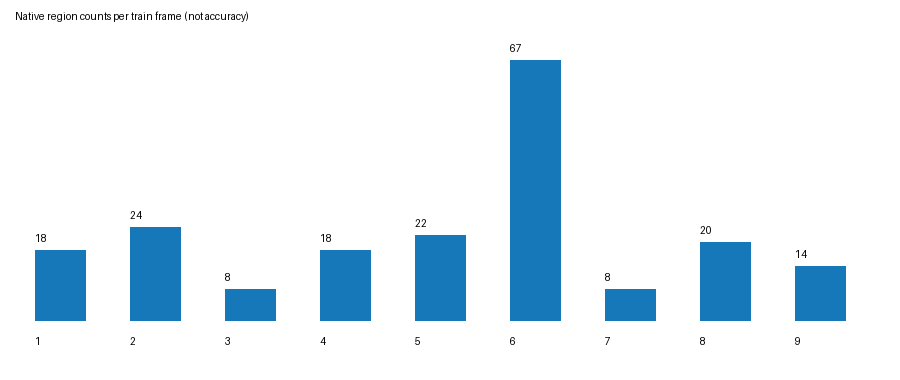

Đã lưu 9 overlays, chart, toàn bộ text/polygon CSV/HTML. Không chấm accuracy; giữ nguyên prediction native lỗi.


In [6]:
import csv, math
summary, all_predictions, html_tables = [], [], []
for index, row in enumerate(observations):
    predictions = row['predictions']
    summary.append({'Frame':index+1, 'Frame ID':row['frame_id'], 'Regions':len(predictions), 'Invalid native':row['invalid_predictions'], 'Wall seconds':round(row['wall_seconds'],3)})
    with Image.open(ROOT/row['frame_id']) as image:
        overlay = image.convert('RGB')
    draw = ImageDraw.Draw(overlay)
    frame_rows = []
    for region_id, prediction in enumerate(predictions, 1):
        points = prediction['polygon']
        renderable = len(points) >= 3 and all(len(p) == 2 and all(math.isfinite(v) for v in p) for p in points)
        if renderable:
            xy = [tuple(p) for p in points]
            draw.line(xy+[xy[0]], fill='#008bff', width=3)
            draw.text(xy[0], str(region_id), fill='#ff2020', stroke_width=1, stroke_fill='white')
        item = {'Frame ID':row['frame_id'], 'Region':region_id, 'Text':prediction['text'], 'Polygon':json.dumps(points), 'Overlay':'drawn' if renderable else 'unrenderable — retained'}
        frame_rows.append(item)
        all_predictions.append(item)
    overlay.save(VIS/f'frame-{index+1:02d}-predictions.png')
    display(HTML('<h3>Frame ' + str(index+1) + ': ' + escape(row['frame_id']) + '</h3>'))
    display(HTML('<p>Native invalid polygons: ' + str(row['invalid_predictions']) + '. Overlay không sửa/lọc prediction; số đỏ tra bảng bên dưới. Không có GT hoặc confidence giả.</p>'))
    display(overlay.resize((min(1200,overlay.width), max(1,round(overlay.height*min(1200,overlay.width)/overlay.width)))))
    html_tables.append(show_table(frame_rows, ['Region','Text','Polygon','Overlay'], 'Toàn bộ transcription native — ' + str(len(predictions)) + ' vùng'))
summary_html = show_table(summary, ['Frame','Frame ID','Regions','Invalid native','Wall seconds'], 'Bước 6 — Tổng hợp 9 frame')
display(HTML('<p>Wall seconds gồm chi phí của từng lời gọi trong preflight; không dùng làm benchmark tốc độ ổn định.</p>'))
# Dependency-free count chart. These counts measure output coverage, not accuracy.
chart = Image.new('RGB', (900,380), 'white')
draw = ImageDraw.Draw(chart)
draw.text((15,10), 'Native region counts per train frame (not accuracy)', fill='black')
maximum = max([r['Regions'] for r in summary]+[1])
for i, row in enumerate(summary):
    x, top = 35+i*95, 320-round(260*row['Regions']/maximum)
    draw.rectangle((x,top,x+50,320), fill='#1678b8')
    draw.text((x,top-18), str(row['Regions']), fill='black')
    draw.text((x,335), str(row['Frame']), fill='black')
chart.save(VIS/'region-counts.png')
display(chart)
(VIS/'prediction-tables.html').write_text('<meta charset="utf-8">'+summary_html+''.join(html_tables), encoding='utf-8')
with (VIS/'predictions.csv').open('w', newline='', encoding='utf-8-sig') as stream:
    writer = csv.DictWriter(stream, fieldnames=['Frame ID','Region','Text','Polygon','Overlay'])
    writer.writeheader()
    writer.writerows(all_predictions)
(VIS/'frame-summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print('Đã lưu 9 overlays, chart, toàn bộ text/polygon CSV/HTML. Không chấm accuracy; giữ nguyên prediction native lỗi.')


## Lưu evidence kể cả khi preflight thất bại

Có thể chạy riêng cell này để tải log và partial receipts. Sau khi xác minh đạt, chuyển sang notebook comparison v2; notebook đó vẫn phải tạo preflight binding riêng cho run test.


In [7]:
import shutil
# Safe to run separately after a failure, provided the hardware cell created OUT.
evidence_files = []
for item in sorted(OUT.rglob('*')):
    if item.is_file() and item.name != 'evidence-manifest.json':
        evidence_files.append({'path':item.relative_to(OUT).as_posix(), 'bytes':item.stat().st_size, 'sha256':hashlib.sha256(item.read_bytes()).hexdigest()})
(OUT/'evidence-manifest.json').write_text(json.dumps({'files':evidence_files, 'passed_receipt_present':(OUT/'pgnet_totaltext_joint_t4/preflight.json').is_file(), 'note':'Partial evidence is not a passed preflight; inspect receipt-gates.json.'}, indent=2))
archive_path = shutil.make_archive('/content/pgnet-t4-preflight-evidence', 'zip', OUT)
show_table(evidence_files, ['path','bytes','sha256'], 'Bước 7 — Evidence sẽ tải (kể cả khi lỗi)')
print('ZIP:', archive_path, 'Bytes:', Path(archive_path).stat().st_size)
print('Nhớ File → Save / Download .ipynb để giữ các outputs hiển thị trong notebook.')
files.download(archive_path)


path,bytes,sha256
hardware.json,155,78d8479ee8c591a9aeda6e162e5db7c98c6ae8f1d99704624cbb6c6e0a38ad64
pgnet_totaltext_joint_t4/preflight.json,96787,262b8a920620e3cbdb562c2db510790dd4ea8b3a7ac3bb50b4efa8e809653c13
pgnet_totaltext_joint_t4/prepared.json,1158148,1b989898781543a4fba7f248b655ba5ca02126295b92d8a6bbd6e0da84d6808e
process-status.json,60,c50c0e9730669b8742f2f1fa7ba3e46a5ab424cb6649cc74f2f906d1625e4356
qualification-manifest.json,22857,e9274768a8921dc8c14948aadbad3469c0eb7659f01cff9829e3f5cfd2121158
qualification.log,40051,03937bbe8c89df3f4f699c833fc5730906825415d8214b94c752fd60f651d9e6
receipt-gates.html,1622,98031de6bbd231835bd5ba468ef4ed697ed9946cdf18c389170e2fd4d7493c0e
receipt-gates.json,752,62af52879e85c1818c5c6ff532b4b78b41bcabab500ece56bfd4940dd4110864
visualizations/frame-01-predictions.png,538395,3f1e3bdf450e570322a301a72d2aa4dcccb4e999421eb3af16ed078c2b70abec
visualizations/frame-02-predictions.png,215226,bd671cd6b05185fb88677a4ca21ece95f306d57bace18078966b26acdd07f0db


ZIP: /content/pgnet-t4-preflight-evidence.zip Bytes: 3584094
Nhớ File → Save / Download .ipynb để giữ các outputs hiển thị trong notebook.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>